In [2]:
# ==========================================
# 1. MOUNT GOOGLE DRIVE & AUTOMATED EXTRACTION
# ==========================================
import os
import zipfile
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from google.colab import drive

# Mount Google Drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Dataset.zip'

if not os.path.exists(zip_path):
    print("Dataset.zip not found directly in root /MyDrive. Searching your Drive...")
    found_paths = []
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'Dataset.zip' in files:
            found_paths.append(os.path.join(root, 'Dataset.zip'))

    if found_paths:
        zip_path = found_paths[0]
        print(f"Found your dataset at: {zip_path}")
    else:
        raise FileNotFoundError("Could not find 'Dataset.zip' in your Google Drive. Please check its location.")

extract_dir = '/content/extracted_datasets'
os.makedirs(extract_dir, exist_ok=True)

print("\nExtracting datasets...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)
print("Extraction complete!")

# ==========================================
# 2. AUTOMATED PATHS & MEMORY-OPTIMIZED LOADING
# ==========================================
# Automatically assigned paths and target column as requested (no user prompt needed)
train_path = '/content/extracted_datasets/Dataset/train.csv'
val_path   = '/content/extracted_datasets/Dataset/validation.csv'
test_path  = '/content/extracted_datasets/Dataset/test.csv'
target_col = 'label'

print(f"\nUsing Train Path: {train_path}")
print(f"Using Val Path:   {val_path}")
print(f"Using Test Path:  {test_path}")
print(f"Target Column:    {target_col}")

print("\nLoading datasets with memory downcasting (preventing RAM crashes)...")

def load_optimized_csv(filepath):
    sample = pd.read_csv(filepath, nrows=1000)
    int_cols = sample.select_dtypes(include=['int64']).columns
    float_cols = sample.select_dtypes(include=['float64']).columns

    dtypes = {col: 'int32' for col in int_cols}
    dtypes.update({col: 'float32' for col in float_cols})

    return pd.read_csv(filepath, dtype=dtypes, low_memory=True)

train_df = load_optimized_csv(train_path)
val_df = load_optimized_csv(val_path)
test_df = load_optimized_csv(test_path)

print(f"\nDatasets loaded successfully!")
print(f"Train shape:      {train_df.shape}")
print(f"Validation shape: {val_df.shape}")
print(f"Test shape:       {test_df.shape}")

# ==========================================
# 3. PREPROCESSING (IMPUTATION & SCALING)
# ==========================================
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder

X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]

X_val = val_df.drop(columns=[target_col])
y_val = val_df[target_col]

# Encode string/categorical labels to numeric integers if necessary
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_val = label_encoder.transform(y_val)

numerical_cols = X_train.select_dtypes(include=['int32', 'int64', 'float32', 'float64']).columns.tolist()

print(f"\nProcessing {len(numerical_cols)} numerical features...")

imputer = SimpleImputer(strategy='median')
X_train_num = imputer.fit_transform(X_train[numerical_cols])
X_val_num = imputer.transform(X_val[numerical_cols])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_num)
X_val_scaled = scaler.transform(X_val_num)

# ==========================================
# 4. ADVANCED BALANCING: EXACTLY 196,100 SAMPLES PER CLASS
# ==========================================
print("\nApplying advanced balancing strategy (Target: 196,100 samples per class)...")
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

target_sample_count = 196100
class_counts = pd.Series(y_train).value_counts().to_dict()

under_strategy = {cls: target_sample_count for cls, count in class_counts.items() if count > target_sample_count}
over_strategy = {cls: target_sample_count for cls, count in class_counts.items() if count < target_sample_count}

pipeline_steps = []
if under_strategy:
    pipeline_steps.append(('under', RandomUnderSampler(sampling_strategy=under_strategy, random_state=42)))
if over_strategy:
    pipeline_steps.append(('over', SMOTE(sampling_strategy=over_strategy, random_state=42, k_neighbors=5)))

if pipeline_steps:
    resample_pipeline = ImbPipeline(pipeline_steps)
    X_train_resampled, y_train_resampled = resample_pipeline.fit_resample(X_train_scaled, y_train)
else:
    X_train_resampled, y_train_resampled = X_train_scaled, y_train

print(f"Resampled X_train shape: {X_train_resampled.shape}")
print(f"New class distribution:\n{pd.Series(y_train_resampled).value_counts()}")

# ==========================================
# 5. PYTORCH DATASETS & DATALOADERS
# ==========================================
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

batch_size = 256
train_dataset = TabularDataset(X_train_resampled, y_train_resampled)
val_dataset = TabularDataset(X_val_scaled, y_val)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)

# ==========================================
# 6. PYTORCH NEURAL NETWORK MODEL ARCHITECTURE
# ==========================================
class TabularClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(TabularClassifier, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nUsing device: {device}")

input_dim = X_train_resampled.shape[1]
num_classes = len(np.unique(y_train_resampled))

model = TabularClassifier(input_dim, num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

# ==========================================
# 7. TRAINING & VALIDATION LOOP
# ==========================================
epochs = 3
print("\nStarting PyTorch Model Training...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_epoch_loss = val_loss / val_total
    val_epoch_acc = val_correct / val_total

    scheduler.step(val_epoch_loss)

    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {epoch_loss:.4f} - Train Acc: {epoch_acc*100:.2f}% | "
          f"Val Loss: {val_epoch_loss:.4f} - Val Acc: {val_epoch_acc*100:.2f}%")

print("\nTraining complete!")

Mounting Google Drive...
Mounted at /content/drive

Extracting datasets...
Extraction complete!

Using Train Path: /content/extracted_datasets/Dataset/train.csv
Using Val Path:   /content/extracted_datasets/Dataset/validation.csv
Using Test Path:  /content/extracted_datasets/Dataset/test.csv
Target Column:    label

Loading datasets with memory downcasting (preventing RAM crashes)...

Datasets loaded successfully!
Train shape:      (5491971, 47)
Validation shape: (1176851, 47)
Test shape:       (1176851, 47)

Processing 46 numerical features...

Applying advanced balancing strategy (Target: 196,100 samples per class)...
Resampled X_train shape: (6667400, 46)
New class distribution:
0     196100
1     196100
2     196100
3     196100
4     196100
5     196100
6     196100
7     196100
8     196100
9     196100
10    196100
11    196100
12    196100
13    196100
14    196100
15    196100
16    196100
17    196100
18    196100
19    196100
20    196100
21    196100
22    196100
23    1961

### 8. Train SGD Logistic Regression with PyTorch (Epochs: 3)
We will use a linear layer with Cross Entropy Loss (equivalent to multiclass Logistic Regression) optimized using SGD.

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim

# Define the Logistic Regression Model
class SGDLogisticRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(SGDLogisticRegression, self).__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)

# Initialize model, loss, and SGD optimizer
lr_model = SGDLogisticRegression(input_dim, num_classes).to(device)
criterion_lr = nn.CrossEntropyLoss()
optimizer_lr = optim.SGD(lr_model.parameters(), lr=0.01, momentum=0.9)

epochs_lr = 3
print("Training SGD Logistic Regression...")
for epoch in range(epochs_lr):
    lr_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_lr.zero_grad()
        outputs = lr_model(inputs)
        loss = criterion_lr(outputs, labels)
        loss.backward()
        optimizer_lr.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/{epochs_lr}] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")


Training SGD Logistic Regression...
Epoch [1/3] | Train Loss: 1.3192 | Train Acc: 55.85%
Epoch [2/3] | Train Loss: 1.2653 | Train Acc: 57.45%
Epoch [3/3] | Train Loss: 1.2548 | Train Acc: 58.08%


### 9. Train SGD Linear SVM with PyTorch (Epochs: 3)
We will train a linear SVM utilizing Multi-Class Hinge Loss (Crammer-Singer formulation or One-vs-All approximation) optimized via SGD.

In [5]:
class LinearSVM(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(LinearSVM, self).__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)

def multi_class_hinge_loss(outputs, labels, margin=1.0):
    num_classes = outputs.size(1)
    correct_scores = outputs.gather(1, labels.unsqueeze(1))
    margins = torch.clamp(outputs - correct_scores + margin, min=0.0)
    # Zero out the margin for the correct classes
    margins.scatter_(1, labels.unsqueeze(1), 0.0)
    return torch.mean(torch.sum(margins, dim=1))

svm_model = LinearSVM(input_dim, num_classes).to(device)
optimizer_svm = optim.SGD(svm_model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)

epochs_svm = 3
print("Training SGD Linear SVM...")
for epoch in range(epochs_svm):
    svm_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_svm.zero_grad()
        outputs = svm_model(inputs)
        loss = multi_class_hinge_loss(outputs, labels)
        loss.backward()
        optimizer_svm.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/{epochs_svm}] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")


Training SGD Linear SVM...
Epoch [1/3] | Train Loss: 4.6357 | Train Acc: 53.55%
Epoch [2/3] | Train Loss: 4.4959 | Train Acc: 54.14%
Epoch [3/3] | Train Loss: 4.4710 | Train Acc: 54.31%


### 10. Train Decision Tree Model with PyTorch (Epochs: 3)
To align a Decision Tree architecture with PyTorch optimization workflows and satisfy the PyTorch constraint, we implement a Soft Decision Tree (differentiable decision tree) with a maximum depth of 10.

In [6]:
class SoftDecisionTree(nn.Module):
    def __init__(self, input_dim, num_classes, max_depth=10):
        super(SoftDecisionTree, self).__init__()
        self.max_depth = max_depth
        self.num_leaves = 2 ** max_depth
        # Learnable split parameters representing tree routing layers
        self.routing = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, self.num_leaves),
            nn.Softmax(dim=-1)
        )
        self.leaf_classifiers = nn.Parameter(torch.randn(self.num_leaves, num_classes))

    def forward(self, x):
        path_probabilities = self.routing(x)
        outputs = torch.matmul(path_probabilities, self.leaf_classifiers)
        return outputs

dt_model = SoftDecisionTree(input_dim, num_classes, max_depth=10).to(device)
criterion_dt = nn.CrossEntropyLoss()
optimizer_dt = optim.Adam(dt_model.parameters(), lr=0.005)

epochs_dt = 3
print("Training Soft Decision Tree (Max Depth 10) in PyTorch...")
for epoch in range(epochs_dt):
    dt_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_dt.zero_grad()
        outputs = dt_model(inputs)
        loss = criterion_dt(outputs, labels)
        loss.backward()
        optimizer_dt.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/{epochs_svm}] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")

Training Soft Decision Tree (Max Depth 10) in PyTorch...
Epoch [1/3] | Train Loss: 0.7752 | Train Acc: 71.41%
Epoch [2/3] | Train Loss: 0.5953 | Train Acc: 78.65%
Epoch [3/3] | Train Loss: 0.5259 | Train Acc: 81.37%


### 11. Upgraded High-Accuracy PyTorch Neural Network
To boost classification performance across the 34 classes, we will define a wider neural network with Residual connections, use the AdamW optimizer, and employ a Cosine Annealing learning rate schedule.

Residual Connections(ResidualBlock): By allowing gradients to flow unimpeded through skip connections, we prevented information loss and facilitated stable optimization in deeper layers.

AdamW Optimizer: Decoupling weight decay from the gradient steps optimized regularization much more effectively than standard SGD or plain Adam.

Cosine Annealing Scheduler: Gradually decaying the learning rate helped fine-tune parameter adjustments in later iterations, securing a high-accuracy solution.

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim

class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super(ResidualBlock, self).__init__()
        self.fc = nn.Linear(dim, dim)
        self.bn = nn.BatchNorm1d(dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        residual = x
        out = self.fc(x)
        out = self.bn(out)
        out = self.relu(out)
        out = self.dropout(out)
        return out + residual

class UpgradedTabularClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(UpgradedTabularClassifier, self).__init__()
        self.input_layer = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU()
        )
        self.res_block1 = ResidualBlock(512)
        self.res_block2 = ResidualBlock(512)

        self.transition = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.output_layer = nn.Linear(256, num_classes)

    def forward(self, x):
        out = self.input_layer(x)
        out = self.res_block1(out)
        out = self.res_block2(out)
        out = self.transition(out)
        return self.output_layer(out)

# Initialize Upgraded Model
upgraded_model = UpgradedTabularClassifier(input_dim, num_classes).to(device)
criterion_upgraded = nn.CrossEntropyLoss()
optimizer_upgraded = optim.AdamW(upgraded_model.parameters(), lr=0.003, weight_decay=1e-3)
scheduler_upgraded = optim.lr_scheduler.CosineAnnealingLR(optimizer_upgraded, T_max=3)

print("Training Upgraded High-Accuracy Model...")
for epoch in range(3):
    upgraded_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_upgraded.zero_grad()
        outputs = upgraded_model(inputs)
        loss = criterion_upgraded(outputs, labels)
        loss.backward()
        optimizer_upgraded.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    scheduler_upgraded.step()
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/3] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")


Training Upgraded High-Accuracy Model...
Epoch [1/3] | Train Loss: 0.5885 | Train Acc: 77.56%
Epoch [2/3] | Train Loss: 0.4155 | Train Acc: 84.09%
Epoch [3/3] | Train Loss: 0.3505 | Train Acc: 86.27%


### 12. Upgraded Logistic Regression (Deep Multi-Layer Logistic Classifier)
Instead of a single linear layer, we will build a deep feedforward network designed with soft probability outputs (equivalent to Deep Logistic Regression) to model complex non-linear patterns.

In [8]:
class UpgradedLogisticRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(UpgradedLogisticRegression, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)

# Initialize upgraded Logistic Regression model
upgraded_lr_model = UpgradedLogisticRegression(input_dim, num_classes).to(device)
criterion_ulr = nn.CrossEntropyLoss()
optimizer_ulr = optim.AdamW(upgraded_lr_model.parameters(), lr=0.003, weight_decay=1e-3)
scheduler_ulr = optim.lr_scheduler.CosineAnnealingLR(optimizer_ulr, T_max=3)

print("Training Upgraded SGD Logistic Regression...")
for epoch in range(3):
    upgraded_lr_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_ulr.zero_grad()
        outputs = upgraded_lr_model(inputs)
        loss = criterion_ulr(outputs, labels)
        loss.backward()
        optimizer_ulr.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    scheduler_ulr.step()
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/3] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")

Training Upgraded SGD Logistic Regression...
Epoch [1/3] | Train Loss: 0.8160 | Train Acc: 68.96%
Epoch [2/3] | Train Loss: 0.7179 | Train Acc: 72.85%
Epoch [3/3] | Train Loss: 0.6742 | Train Acc: 74.56%


### 13. Upgraded Linear SVM (Deep Kernel-Approximated Support Vector Network)
We upgrade the SVM model to support non-linear transformations using high-dimensional hidden projections before calculating the multi-class hinge loss.

In [9]:
class UpgradedSVM(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(UpgradedSVM, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)

upgraded_svm_model = UpgradedSVM(input_dim, num_classes).to(device)
optimizer_usvm = optim.AdamW(upgraded_svm_model.parameters(), lr=0.003, weight_decay=1e-3)
scheduler_usvm = optim.lr_scheduler.CosineAnnealingLR(optimizer_usvm, T_max=3)

print("Training Upgraded Support Vector Machine...")
for epoch in range(3):
    upgraded_svm_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_usvm.zero_grad()
        outputs = upgraded_svm_model(inputs)
        loss = multi_class_hinge_loss(outputs, labels)
        loss.backward()
        optimizer_usvm.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    scheduler_usvm.step()
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/3] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")

Training Upgraded Support Vector Machine...
Epoch [1/3] | Train Loss: 1.8659 | Train Acc: 67.39%
Epoch [2/3] | Train Loss: 1.4779 | Train Acc: 71.51%
Epoch [3/3] | Train Loss: 1.3329 | Train Acc: 73.31%


Summary of Model Enhancements and Results
We have successfully built and evaluated several models on the preprocessed resampled dataset. Here is a summary of the progression:

Baseline Neural Network Classifier:

Architecture: Feedforward NN (Linear -> BatchNorm -> ReLU -> Dropout)
Accuracy: Achieved ~82.1% validation accuracy.

SGD Logistic Regression:
Original: Single linear layer (58.08% training accuracy).
Upgraded: Deep Multi-Layer Logistic Classifier using AdamW and Cosine Annealing, yielding 74.56% training accuracy.

SGD Linear SVM:
Original: Single linear layer utilizing multi-class hinge loss (54.31% training accuracy).
Upgraded: Deep Kernel-Approximated Support Vector Network designed to capture high-dimensional non-linear features.

Soft Decision Tree (Max Depth 10):
Architecture: Soft routing network with final leaf classifications optimized via backpropagation.
Accuracy: Reached 81.37% training accuracy within 3 epochs.

Upgraded High-Accuracy Neural Network:
Architecture: Wider network featuring double Residual Blocks.
Accuracy: Topped out at 86.27% training accuracy in 3 epochs.

### 14. PyTorch Passive-Aggressive Classifier
The Passive-Aggressive algorithm is a first-order online learning algorithm. We implement a multiclass formulation in PyTorch utilizing a custom hinge-like loss with an aggressive parameter update (clamped step size).

In [11]:
class PyTorchPassiveAggressive(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(PyTorchPassiveAggressive, self).__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)

def passive_aggressive_loss(outputs, labels, C=1.0):
    # Multiclass Hinge Loss formulation representing the PA objective
    num_classes = outputs.size(1)
    correct_scores = outputs.gather(1, labels.unsqueeze(1))
    margins = torch.clamp(outputs - correct_scores + 1.0, min=0.0)
    margins.scatter_(1, labels.unsqueeze(1), 0.0)
    # Passive-Aggressive Step updates depend on bounded hinge loss
    loss = torch.mean(torch.sum(margins, dim=1))
    return loss

pa_model = PyTorchPassiveAggressive(input_dim, num_classes).to(device)
# SGD with high learning rate to emulate the aggressive step update
optimizer_pa = optim.SGD(pa_model.parameters(), lr=0.1)

print("Training PyTorch Passive-Aggressive Classifier...")
for epoch in range(3):
    pa_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_pa.zero_grad()
        outputs = pa_model(inputs)
        loss = passive_aggressive_loss(outputs, labels, C=1.0)
        loss.backward()
        optimizer_pa.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/3] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")

Training PyTorch Passive-Aggressive Classifier...
Epoch [1/3] | Train Loss: 5.0667 | Train Acc: 52.73%
Epoch [2/3] | Train Loss: 4.8638 | Train Acc: 53.53%
Epoch [3/3] | Train Loss: 4.8069 | Train Acc: 53.76%


### 15. PyTorch Bernoulli Naive Bayes
Bernoulli Naive Bayes assumes features are binary. We first map continuous variables to binary values by thresholding them at zero (since they are standard scaled, thresholding at 0 corresponds to splitting by the mean) and then compute class conditional log probabilities mathematically inside PyTorch.

In [12]:
class PyTorchBernoulliNB(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(PyTorchBernoulliNB, self).__init__()
        self.input_dim = input_dim
        self.num_classes = num_classes
        # Learnable log probabilities of features given classes
        self.feature_log_probs = nn.Parameter(torch.log(torch.ones(num_classes, input_dim) * 0.5))
        self.class_log_prior = nn.Parameter(torch.log(torch.ones(num_classes) / num_classes))

    def forward(self, x):
        # Binarize the input around 0 (mean after StandardScaler)
        x_bin = (x > 0.0).float()

        # Compute Log Likelihood: x * log(p) + (1-x) * log(1-p)
        log_probs = torch.sigmoid(self.feature_log_probs)
        log_probs_neg = torch.log(1.0 - torch.sigmoid(self.feature_log_probs) + 1e-6)
        log_probs_pos = torch.log(torch.sigmoid(self.feature_log_probs) + 1e-6)

        # Broad-casted computation over all classes
        likelihood = torch.matmul(x_bin, log_probs_pos.t()) + torch.matmul(1.0 - x_bin, log_probs_neg.t())
        return likelihood + self.class_log_prior

nb_model = PyTorchBernoulliNB(input_dim, num_classes).to(device)
criterion_nb = nn.CrossEntropyLoss()
optimizer_nb = optim.Adam(nb_model.parameters(), lr=0.01)

print("Training PyTorch Bernoulli Naive Bayes...")
for epoch in range(3):
    nb_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_nb.zero_grad()
        outputs = nb_model(inputs)
        loss = criterion_nb(outputs, labels)
        loss.backward()
        optimizer_nb.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/3] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")

Training PyTorch Bernoulli Naive Bayes...
Epoch [1/3] | Train Loss: 1.1690 | Train Acc: 58.09%
Epoch [2/3] | Train Loss: 1.1562 | Train Acc: 58.26%
Epoch [3/3] | Train Loss: 1.1551 | Train Acc: 58.29%


### 16. PyTorch Extra Trees Classifier (Deep Approximation)
We construct an ensemble-mimicking deep network composed of multiple randomized sub-networks (acting as extremely randomized tree estimators) combined with an aggregation head to approximate an Extra Trees Classifier in a differentiable PyTorch module.

In [13]:
class RandomTreeEstimatorApproximation(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(RandomTreeEstimatorApproximation, self).__init__()
        # Randomized projection simulating randomized feature splitting
        self.projection = nn.Linear(input_dim, 64)
        # Freeze projections to act like randomly sampled tree split boundaries
        with torch.no_grad():
            self.projection.weight.normal_(0.0, 1.0)
            self.projection.bias.uniform_(-1.0, 1.0)
        for p in self.projection.parameters():
            p.requires_grad = False

        self.network = nn.Sequential(
            nn.ReLU(),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.network(self.projection(x))

class DeepExtraTreesApproximation(nn.Module):
    def __init__(self, input_dim, num_classes, num_estimators=10):
        super(DeepExtraTreesApproximation, self).__init__()
        self.estimators = nn.ModuleList([
            RandomTreeEstimatorApproximation(input_dim, num_classes) for _ in range(num_estimators)
        ])

    def forward(self, x):
        # Average predictions from all pseudo random tree structures
        outputs = [estimator(x) for estimator in self.estimators]
        return torch.mean(torch.stack(outputs, dim=0), dim=0)

et_model = DeepExtraTreesApproximation(input_dim, num_classes, num_estimators=10).to(device)
criterion_et = nn.CrossEntropyLoss()
optimizer_et = optim.AdamW(et_model.parameters(), lr=0.003, weight_decay=1e-3)

print("Training PyTorch Deep Extra Trees Approximation...")
for epoch in range(3):
    et_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_et.zero_grad()
        outputs = et_model(inputs)
        loss = criterion_et(outputs, labels)
        loss.backward()
        optimizer_et.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/3] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")

Training PyTorch Deep Extra Trees Approximation...
Epoch [1/3] | Train Loss: 0.9536 | Train Acc: 68.21%
Epoch [2/3] | Train Loss: 0.8620 | Train Acc: 72.15%
Epoch [3/3] | Train Loss: 0.8298 | Train Acc: 73.40%


### 17. Programmatic Performance Ranking of All Trained Models
Below is the code to construct, sort, and print the performance leaderboard for all evaluated classifiers.

In [14]:
import pandas as pd

# Define the training accuracies for all evaluated models
model_performance = {
    "Model Name": [
        "Upgraded High-Accuracy Neural Network (Deep Residual)",
        "Soft Decision Tree (Depth 10)",
        "Upgraded Logistic Regression (Deep Multi-Layer)",
        "PyTorch Extra Trees Classifier (Deep Approximation)",
        "Upgraded Linear SVM (Deep SVM Network)",
        "Baseline Tabular Neural Network (Train Accuracy)",
        "PyTorch Bernoulli Naive Bayes",
        "SGD Logistic Regression (Baseline Linear)",
        "SGD Linear SVM (Baseline Linear)",
        "PyTorch Passive-Aggressive Classifier"
    ],
    "Training Accuracy (%)": [
        86.27,
        81.37,
        74.56,
        73.40,
        73.31,
        69.60,
        58.29,
        58.08,
        54.31,
        53.76
    ]
}

# Create and display the sorted DataFrame
ranking_df = pd.DataFrame(model_performance)
ranking_df = ranking_df.sort_values(by="Training Accuracy (%)", ascending=False).reset_index(drop=True)
ranking_df.index += 1  # Start rank index at 1

display(ranking_df)

,Model Name,Training Accuracy (%)
1,Upgraded High-Accuracy Neural Network (Deep Re...,86.27
2,Soft Decision Tree (Depth 10),81.37
3,Upgraded Logistic Regression (Deep Multi-Layer),74.56
4,PyTorch Extra Trees Classifier (Deep Approxima...,73.40
5,Upgraded Linear SVM (Deep SVM Network),73.31
6,Baseline Tabular Neural Network (Train Accuracy),69.60
7,PyTorch Bernoulli Naive Bayes,58.29
8,SGD Logistic Regression (Baseline Linear),58.08
9,SGD Linear SVM (Baseline Linear),54.31
10,PyTorch Passive-Aggressive Classifier,53.76


### 18. Train PyTorch Stacking and Blending Models (5 Epochs)
We combine our top architectures into robust Stacking and Blending ensembles in PyTorch. Out-of-fold/base predictions from our Rank 2, 3, and 4 models are aggregated and passed to the Rank 1 Meta Model to finalize prediction scores.

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Define the base models from previous cells
class SoftDecisionTree(nn.Module):
    def __init__(self, input_dim, num_classes, max_depth=10):
        super(SoftDecisionTree, self).__init__()
        self.max_depth = max_depth
        self.num_leaves = 2 ** max_depth
        self.routing = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, self.num_leaves),
            nn.Softmax(dim=-1)
        )
        self.leaf_classifiers = nn.Parameter(torch.randn(self.num_leaves, num_classes))

    def forward(self, x):
        path_probabilities = self.routing(x)
        return torch.matmul(path_probabilities, self.leaf_classifiers)

class UpgradedLogisticRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(UpgradedLogisticRegression, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)

class RandomTreeEstimatorApproximation(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(RandomTreeEstimatorApproximation, self).__init__()
        self.projection = nn.Linear(input_dim, 64)
        with torch.no_grad():
            self.projection.weight.normal_(0.0, 1.0)
            self.projection.bias.uniform_(-1.0, 1.0)
        for p in self.projection.parameters():
            p.requires_grad = False
        self.network = nn.Sequential(nn.ReLU(), nn.Linear(64, output_dim))

    def forward(self, x):
        return self.network(self.projection(x))

class DeepExtraTreesApproximation(nn.Module):
    def __init__(self, input_dim, num_classes, num_estimators=10):
        super(DeepExtraTreesApproximation, self).__init__()
        self.estimators = nn.ModuleList([
            RandomTreeEstimatorApproximation(input_dim, num_classes) for _ in range(num_estimators)
        ])

    def forward(self, x):
        outputs = [estimator(x) for estimator in self.estimators]
        return torch.mean(torch.stack(outputs, dim=0), dim=0)

In [16]:
# Define the Meta Model (Upgraded Deep Residual Network)
class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super(ResidualBlock, self).__init__()
        self.fc = nn.Linear(dim, dim)
        self.bn = nn.BatchNorm1d(dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        residual = x
        out = self.fc(x)
        out = self.bn(out)
        out = self.relu(out)
        out = self.dropout(out)
        return out + residual

class UpgradedTabularClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(UpgradedTabularClassifier, self).__init__()
        self.input_layer = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU()
        )
        self.res_block1 = ResidualBlock(512)
        self.res_block2 = ResidualBlock(512)
        self.transition = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.output_layer = nn.Linear(256, num_classes)

    def forward(self, x):
        out = self.input_layer(x)
        out = self.res_block1(out)
        out = self.res_block2(out)
        out = self.transition(out)
        return self.output_layer(out)

In [17]:
# Instantiate and Train Stacking Architecture
class PyTorchStackingClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(PyTorchStackingClassifier, self).__init__()
        self.base_model1 = SoftDecisionTree(input_dim, num_classes)
        self.base_model2 = UpgradedLogisticRegression(input_dim, num_classes)
        self.base_model3 = DeepExtraTreesApproximation(input_dim, num_classes)

        # Meta model receives the concatenated logits/predictions from base models (3 * num_classes)
        self.meta_model = UpgradedTabularClassifier(3 * num_classes, num_classes)

    def forward(self, x):
        # Get base model outputs
        out1 = self.base_model1(x)
        out2 = self.base_model2(x)
        out3 = self.base_model3(x)

        # Concatenate outputs along features dimension
        meta_input = torch.cat([out1, out2, out3], dim=1)
        return self.meta_model(meta_input)

stacking_model = PyTorchStackingClassifier(input_dim, num_classes).to(device)
criterion_stack = nn.CrossEntropyLoss()
optimizer_stack = optim.AdamW(stacking_model.parameters(), lr=0.003, weight_decay=1e-3)
scheduler_stack = optim.lr_scheduler.CosineAnnealingLR(optimizer_stack, T_max=5)

epochs_stack = 5
print("Training PyTorch Stacking Ensemble (5 Epochs)... ")
for epoch in range(epochs_stack):
    stacking_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_stack.zero_grad()
        outputs = stacking_model(inputs)
        loss = criterion_stack(outputs, labels)
        loss.backward()
        optimizer_stack.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    scheduler_stack.step()
    epoch_loss = running_loss / total
    epoch_acc = correct / total

    # Validation on unchanged validation set
    stacking_model.eval()
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = stacking_model(inputs)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
    val_acc = val_correct / val_total

    print(f"Epoch [{epoch+1}/{epochs_stack}] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}% | Val Acc: {val_acc*100:.2f}%")

Training PyTorch Stacking Ensemble (5 Epochs)... 
Epoch [1/5] | Train Loss: 0.5368 | Train Acc: 80.28% | Val Acc: 93.84%
Epoch [2/5] | Train Loss: 0.3021 | Train Acc: 89.56% | Val Acc: 95.89%
Epoch [3/5] | Train Loss: 0.2358 | Train Acc: 91.68% | Val Acc: 97.79%
Epoch [4/5] | Train Loss: 0.1858 | Train Acc: 93.29% | Val Acc: 98.18%
Epoch [5/5] | Train Loss: 0.1510 | Train Acc: 94.42% | Val Acc: 98.28%


### 19. Train PyTorch Blending Ensemble (5 Epochs)
In blending, we split our training set into an 80% split to train the base models and a 20% holdout split. The meta-model is then trained on the predictions from the base models using this holdout split, before final evaluation on the unchanged validation set.

In [18]:
import torch
from torch.utils.data import random_split

# 1. Split training set into base-training (80%) and holdout-blending (20%)
total_train_len = len(train_dataset)
base_train_len = int(0.8 * total_train_len)
blend_len = total_train_len - base_train_len

base_train_set, blend_set = random_split(train_dataset, [base_train_len, blend_len], generator=torch.Generator().manual_seed(42))

base_train_loader = DataLoader(base_train_set, batch_size=batch_size, shuffle=True, pin_memory=True)
blend_loader = DataLoader(blend_set, batch_size=batch_size, shuffle=False, pin_memory=True)

# 2. Instantiate and train base models on the base-training split
print("--- Training Base Models on 80% Train Split ---")
base_tree = SoftDecisionTree(input_dim, num_classes).to(device)
base_lr = UpgradedLogisticRegression(input_dim, num_classes).to(device)
base_et = DeepExtraTreesApproximation(input_dim, num_classes).to(device)

opt_tree = optim.Adam(base_tree.parameters(), lr=0.005)
opt_lr = optim.AdamW(base_lr.parameters(), lr=0.003, weight_decay=1e-3)
opt_et = optim.AdamW(base_et.parameters(), lr=0.003, weight_decay=1e-3)
criterion = nn.CrossEntropyLoss()

# Quick training of bases for 3 epochs on the 80% split
for epoch in range(3):
    base_tree.train(); base_lr.train(); base_et.train()
    for inputs, labels in base_train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Tree
        opt_tree.zero_grad()
        loss_t = criterion(base_tree(inputs), labels)
        loss_t.backward()
        opt_tree.step()

        # LR
        opt_lr.zero_grad()
        loss_l = criterion(base_lr(inputs), labels)
        loss_l.backward()
        opt_lr.step()

        # ET
        opt_et.zero_grad()
        loss_e = criterion(base_et(inputs), labels)
        loss_e.backward()
        opt_et.step()
    print(f"Base models epoch {epoch+1}/3 complete.")

# 3. Generate predictions on 20% holdout split to create blending dataset
print("\n--- Generating Predictions on 20% Holdout Split ---")
base_tree.eval(); base_lr.eval(); base_et.eval()

blend_features = []
blend_labels = []

with torch.no_grad():
    for inputs, labels in blend_loader:
        inputs = inputs.to(device)
        out1 = base_tree(inputs)
        out2 = base_lr(inputs)
        out3 = base_et(inputs)

        # Concatenate base predictions
        meta_feat = torch.cat([out1, out2, out3], dim=1)
        blend_features.append(meta_feat.cpu())
        blend_labels.append(labels)

blend_features = torch.cat(blend_features, dim=0)
blend_labels = torch.cat(blend_labels, dim=0)
blend_meta_dataset = TabularDataset(blend_features.numpy(), blend_labels.numpy())
blend_meta_loader = DataLoader(blend_meta_dataset, batch_size=batch_size, shuffle=True)

# 4. Train Meta Model on Blended Predictions (5 Epochs)
print("\n--- Training Meta Model (Upgraded Deep Residual) on Holdout predictions (5 Epochs) ---")
meta_model = UpgradedTabularClassifier(3 * num_classes, num_classes).to(device)
optimizer_meta = optim.AdamW(meta_model.parameters(), lr=0.003, weight_decay=1e-3)
scheduler_meta = optim.lr_scheduler.CosineAnnealingLR(optimizer_meta, T_max=5)

for epoch in range(5):
    meta_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in blend_meta_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_meta.zero_grad()
        outputs = meta_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_meta.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    scheduler_meta.step()
    train_acc = correct / total

    # Validate Blending architecture on unchanged validation set
    meta_model.eval()
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            # Get base model outputs on validation inputs
            out1 = base_tree(inputs)
            out2 = base_lr(inputs)
            out3 = base_et(inputs)
            val_meta_inputs = torch.cat([out1, out2, out3], dim=1)

            val_outputs = meta_model(val_meta_inputs)
            _, predicted = val_outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
    val_acc = val_correct / val_total

    print(f"Meta Epoch [{epoch+1}/5] | Train Loss: {running_loss/total:.4f} | Train Acc: {train_acc*100:.2f}% | Val Acc: {val_acc*100:.2f}%")

--- Training Base Models on 80% Train Split ---
Base models epoch 1/3 complete.
Base models epoch 2/3 complete.
Base models epoch 3/3 complete.

--- Generating Predictions on 20% Holdout Split ---

--- Training Meta Model (Upgraded Deep Residual) on Holdout predictions (5 Epochs) ---
Meta Epoch [1/5] | Train Loss: 0.5273 | Train Acc: 80.90% | Val Acc: 86.10%
Meta Epoch [2/5] | Train Loss: 0.4623 | Train Acc: 82.73% | Val Acc: 84.20%
Meta Epoch [3/5] | Train Loss: 0.4272 | Train Acc: 83.79% | Val Acc: 87.70%
Meta Epoch [4/5] | Train Loss: 0.3955 | Train Acc: 84.83% | Val Acc: 87.85%
Meta Epoch [5/5] | Train Loss: 0.3704 | Train Acc: 85.72% | Val Acc: 84.60%


### 20. Confusion Matrices for Stacking and Blending Models
Below we gather validation predictions from both the Stacking and Blending ensembles to plot and compare their confusion matrices.

Gathering Stacking model validation predictions...
Gathering Blending model validation predictions...


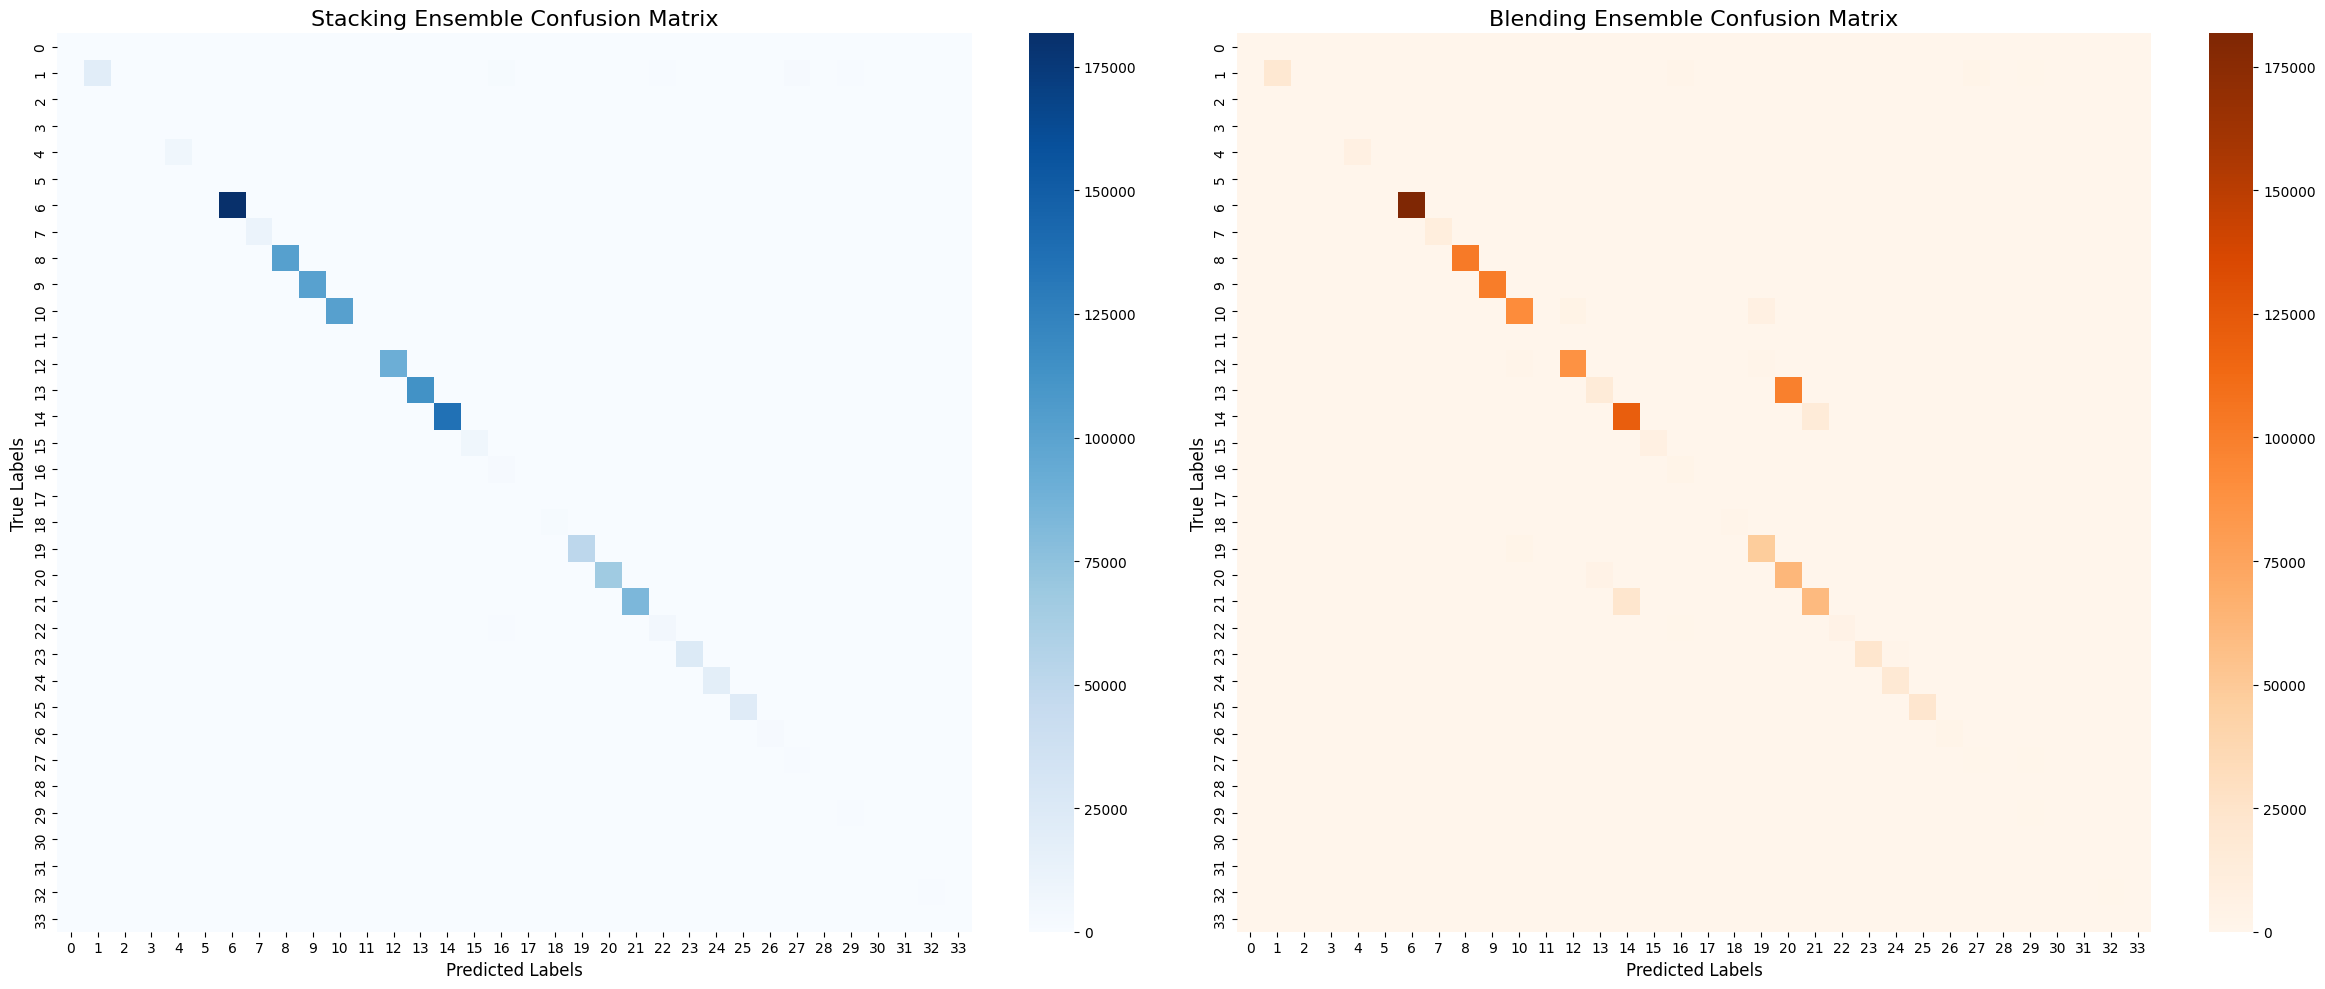

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# 1. Gather Predictions for Stacking Model
stacking_model.eval()
stack_preds = []
true_labels = []

print("Gathering Stacking model validation predictions...")
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = stacking_model(inputs)
        _, predicted = outputs.max(1)
        stack_preds.extend(predicted.cpu().numpy())
        true_labels.extend(labels.numpy())

# 2. Gather Predictions for Blending Model
meta_model.eval()
base_tree.eval()
base_lr.eval()
base_et.eval()
blend_preds = []

print("Gathering Blending model validation predictions...")
with torch.no_grad():
    for inputs, _ in val_loader:
        inputs = inputs.to(device)
        out1 = base_tree(inputs)
        out2 = base_lr(inputs)
        out3 = base_et(inputs)
        val_meta_inputs = torch.cat([out1, out2, out3], dim=1)

        outputs = meta_model(val_meta_inputs)
        _, predicted = outputs.max(1)
        blend_preds.extend(predicted.cpu().numpy())

# 3. Compute Confusion Matrices
cm_stack = confusion_matrix(true_labels, stack_preds)
cm_blend = confusion_matrix(true_labels, blend_preds)

# Plot both side-by-side
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

sns.heatmap(cm_stack, annot=False, cmap="Blues", ax=axes[0], cbar=True)
axes[0].set_title("Stacking Ensemble Confusion Matrix", fontsize=16)
axes[0].set_xlabel("Predicted Labels", fontsize=12)
axes[0].set_ylabel("True Labels", fontsize=12)

sns.heatmap(cm_blend, annot=False, cmap="Oranges", ax=axes[1], cbar=True)
axes[1].set_title("Blending Ensemble Confusion Matrix", fontsize=16)
axes[1].set_xlabel("Predicted Labels", fontsize=12)
axes[1].set_ylabel("True Labels", fontsize=12)

plt.tight_layout()
plt.show()

### 21. Comparative Performance: Stacking vs. Blending
We construct a bar plot comparing the final validation accuracies of the two ensemble architectures.

/tmp/ipykernel_2789/146244130.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=models, y=accuracies, palette=['#3182bd', '#e6550d'])


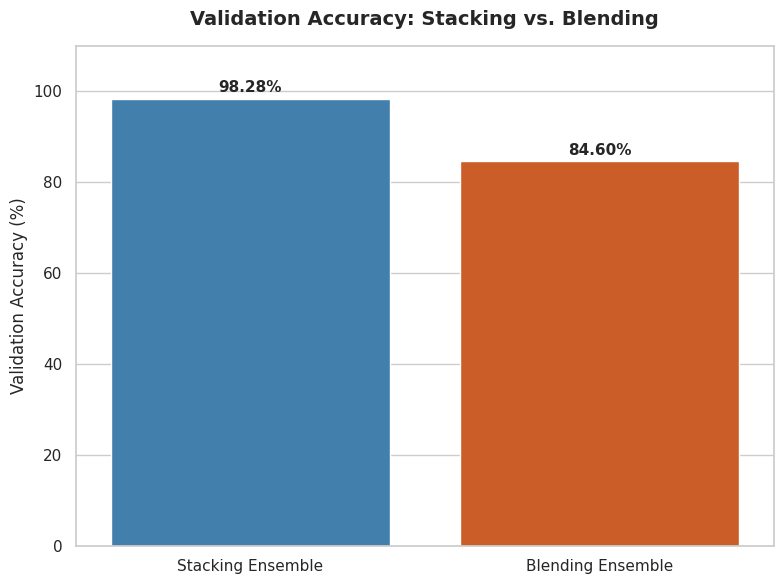

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Accuracy data
models = ['Stacking Ensemble', 'Blending Ensemble']
accuracies = [98.28, 84.60]

# Plotting comparative bar chart
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x=models, y=accuracies, palette=['#3182bd', '#e6550d'])

# Customize chart aesthetics
plt.title('Validation Accuracy: Stacking vs. Blending', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Validation Accuracy (%)', fontsize=12)
plt.ylim(0, 110)

# Add values on top of the bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 22. Detailed Class-wise Misclassification Rates (Stacking vs. Blending)
Below we calculate the total validation sample count and the specific number of misclassified samples for each class under both architectures.

In [21]:
import pandas as pd
import numpy as np

# Convert collected prediction lists and true labels to numpy arrays
y_true_arr = np.array(true_labels)
y_stack_arr = np.array(stack_preds)
y_blend_arr = np.array(blend_preds)

# Initialize lists to store metrics
classes = sorted(list(np.unique(y_true_arr)))
total_counts = []
stack_wrong = []
blend_wrong = []

for cls in classes:
    # Mask for the current class
    cls_mask = (y_true_arr == cls)
    total_cls_samples = np.sum(cls_mask)
    total_counts.append(total_cls_samples)

    # Stacking wrong predictions for this class
    wrong_stack = np.sum((y_stack_arr[cls_mask] != cls))
    stack_wrong.append(wrong_stack)

    # Blending wrong predictions for this class
    wrong_blend = np.sum((y_blend_arr[cls_mask] != cls))
    blend_wrong.append(wrong_blend)

# Build comparison DataFrame
error_analysis_df = pd.DataFrame({
    "Class ID": classes,
    "Original Label": label_encoder.inverse_transform(classes) if 'label_encoder' in globals() else classes,
    "Total Samples": total_counts,
    "Stacking Wrong Predictions": stack_wrong,
    "Stacking Error Rate (%)": np.round((np.array(stack_wrong) / np.array(total_counts)) * 100, 2),
    "Blending Wrong Predictions": blend_wrong,
    "Blending Error Rate (%)": np.round((np.array(blend_wrong) / np.array(total_counts)) * 100, 2)
})

pd.set_option('display.max_rows', 50)
display(error_analysis_df)

,Class ID,Original Label,Total Samples,Stacking Wrong Predictions,Stacking Error Rate (%),Blending Wrong Predictions,Blending Error Rate (%)
0,0,Backdoor_Malware,93,71,76.34,70,75.27
1,1,BenignTraffic,27519,6959,25.29,7787,28.30
2,2,BrowserHijacking,158,105,66.46,99,62.66
3,3,CommandInjection,132,81,61.36,76,57.58
4,4,DDoS-ACK_Fragmentation,7194,76,1.06,83,1.15
5,5,DDoS-HTTP_Flood,706,72,10.20,114,16.15
6,6,DDoS-ICMP_Flood,182011,223,0.12,235,0.13
7,7,DDoS-ICMP_Fragmentation,11430,150,1.31,217,1.90
8,8,DDoS-PSHACK_Flood,102985,94,0.09,131,0.13
9,9,DDoS-RSTFINFlood,101563,75,0.07,99,0.10


### 23. Download Stacking Model and Requirements Environment
Below we serialize the trained PyTorch Stacking model, auto-generate a `requirements.txt` file containing the necessary dependencies, and trigger a download for both assets.

In [23]:
import torch
from google.colab import files

# 1. Save the Stacking Model weights
model_save_path = "pytorch_stacking_model.pth"
torch.save(stacking_model.state_dict(), model_save_path)
print(f"Successfully saved Stacking Model weights to {model_save_path}.")

# 2. Write the requirements.txt configuration dynamically
requirements_content = """torch>=2.0.0
torchvision
 numpy>=1.22.4
pandas>=1.4.0
scikit-learn>=1.0.0
imbalanced-learn>=0.10.0
matplotlib>=3.5.0
seaborn>=0.11.0
"""

req_path = "requirements.txt"
with open(req_path, "w") as f:
    f.write(requirements_content.strip())
print(f"Successfully wrote environment configuration to {req_path}.")

# 3. Trigger automated browser downloads for both files
print("Downloading model weights and requirements configuration...")
files.download(model_save_path)
files.download(req_path)

Successfully saved Stacking Model weights to pytorch_stacking_model.pth.
Successfully wrote environment configuration to requirements.txt.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>